# Traveling-wave MZM at 56 Gbaud

Build a ten-section traveling-wave modulator, calculate its small-signal response, then simulate a 56 Gbaud NRZ eye. Each PN phase shifter contains junction capacitance, native optical delay and a quadratic phase-versus-voltage law. Optical loss is constant.

This introductory example uses an illustrative constant-loss RF line. For the supplied notebooks' dispersive line, vector fitting and a direct RLC reconstruction, see [the reference tutorial](traveling_wave_mzm_reference.ipynb).

Tested with Circulax 0.2.5. Install `circulax>=0.2.5` and `ipykernel` in the notebook kernel environment.

In [1]:
import copy
import time
from importlib.metadata import version

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from circulax import compile_circuit
from circulax.components.base_component import component
from circulax.components.electronic import WAVE_PWL, Capacitor, Resistor, TransmissionLine, WaveformVoltageSource
from circulax.components.photonic import OpticalSource

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True})
print("Circulax:", version("circulax"))
print("JAX:", jax.__version__, "on", jax.default_backend())

Circulax: 0.2.5
JAX: 0.7.2 on cpu


## One section

```text
RF ─ TL(Δz/2) ─●─ TL(Δz/2) ─ RF
               Rj
               ● anode
               Cj  ← inside the phase-shifter component
               ⏚ cathode
Light ─ delayed phase-shifter waveguide(Δz) ─
```

The voltage across the junction capacitor controls optical phase. Two internal half-flight reads place the interaction at the section center. A passive reference arm and ideal 50/50 splitter/combiner give

$$E_\mathrm{out}=(E_\mathrm{active}+jE_\mathrm{reference})/2.$$

The factor 1/2 includes both couplers; the $j$ sets quadrature bias. Matched 1 Ω optical-envelope loads suppress reflections.

In [2]:
c0 = 299_792_458.0
n_sections = 10
length_m = 2e-3
dz = length_m / n_sections
z_rf = 60.0  # unloaded line impedance, ohm
n_rf = 2.2  # unloaded microwave index
n_opt = 4.05  # optical group index
source_r = load_r = 50.0
rf_loss_db = 1.0  # constant full-length wave attenuation
cj_per_m = 320e-12  # F/m
rj_length_product = 4.7e-3  # ohm m: Rj = product / dz
power_w = 1e-3
optical_loss_db_cm = 1.0
v_bias = -1.0  # junction DC voltage
source_vpp = 4.0  # open-circuit drive; ~2 Vpp after matched divider
phase_a1 = 1.2  # rad / (V mm)
phase_a2 = 0.15  # rad / (V^2 mm)
length_mm = length_m * 1e3
slope_per_mm = phase_a1 + 2 * phase_a2 * v_bias
optical_tof = length_m * n_opt / c0
transmitted_power = power_w * 10 ** (-optical_loss_db_cm * length_m * 100 / 10)
print(f"Section: {dz * 1e6:.0f} um, Rj={rj_length_product / dz:.1f} ohm, Cj={cj_per_m * dz * 1e15:.1f} fF")
print(f"Optical flight time: {optical_tof * 1e12:.2f} ps")

Section: 200 um, Rj=23.5 ohm, Cj=64.0 fF
Optical flight time: 27.02 ps


## Small-signal response

Drive the electrical circuit with a 1 V peak open-circuit source phasor, including the source resistance and termination. Let $H_k=V_{j,k}/V_s$.

For each section,

$$\Delta\phi_k=\Delta z_\mathrm{mm}[a_1(V-V_{b,k})+a_2(V^2-V_{b,k}^2)].$$

The output-power response at quadrature is

$$H_{PV}=\frac{P_\mathrm{through}}2\Delta z_\mathrm{mm}
\sum_k(a_1+2a_2V_{b,k})H_k e^{-j2\pi f(L-z_k)n_g/c}.$$

We calculate this voltage-integration reference explicitly because `ac_response` currently excludes non-holomorphic mixed optical circuits.

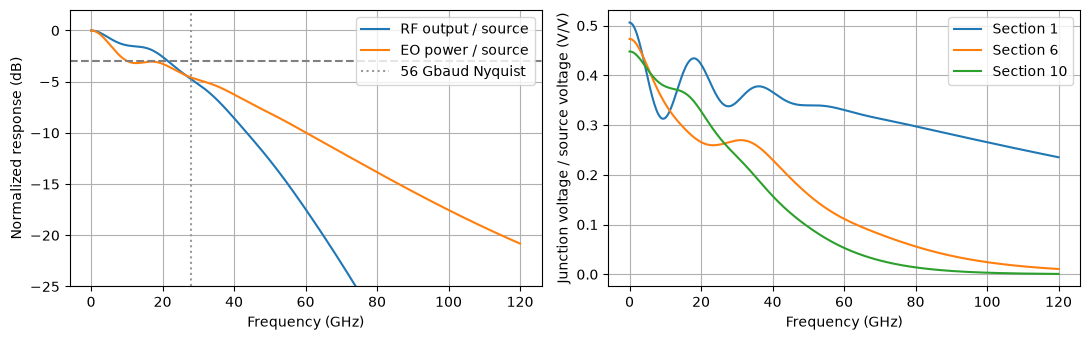

Low-frequency EO slope: 0.4158 mW/V (source-referred)


In [3]:
def electrical_netlist():
    instances = {
        "GND": {"component": "ground"},
        "VS": {"component": "drive", "settings": {"dc": 2 * v_bias}},
        "RS": {"component": "resistor", "settings": {"R": source_r}},
        "RL": {"component": "resistor", "settings": {"R": load_r}},
    }
    connections = {"VS,p1": "RS,p1"}
    grounded = ["VS,p2", "RL,p2"]
    ports = {}
    last = "RS,p2"
    for k in range(n_sections):
        for side in ("a", "b"):
            instances[f"TL{k}{side}"] = {
                "component": "line",
                "settings": {
                    "tau": dz * n_rf / (2 * c0),
                    "z0": z_rf,
                    "attenuation": 10 ** (-rf_loss_db / (40 * n_sections)),
                },
            }
        instances[f"RJ{k}"] = {"component": "resistor", "settings": {"R": rj_length_product / dz}}
        instances[f"CJ{k}"] = {"component": "capacitor", "settings": {"C": cj_per_m * dz}}
        connections[last] = f"TL{k}a,p1"
        connections[f"TL{k}a,p2"] = (f"RJ{k},p1", f"TL{k}b,p1")
        connections[f"RJ{k},p2"] = f"CJ{k},p1"
        grounded.append(f"CJ{k},p2")
        ports[f"junction_{k}"] = f"CJ{k},p1"
        last = f"TL{k}b,p2"
    connections[last] = "RL,p1"
    connections["GND,p1"] = tuple(grounded)
    ports.update(rf_input="TL0a,p1", rf_output=last)
    return {"instances": instances, "connections": connections, "ports": ports}


models = {"drive": WaveformVoltageSource, "resistor": Resistor, "capacitor": Capacitor, "line": TransmissionLine}
rf_net = electrical_netlist()
rf_circuit = compile_circuit(rf_net, models, is_complex=False)
freqs = jnp.linspace(1e6, 120e9, 401)
ac = rf_circuit.ac_response(freqs=freqs, sources={"VS": 1.0})
h_junction = np.stack([np.asarray(rf_circuit.port(ac["solution"], f"junction_{k}")) for k in range(n_sections)], axis=1)
section_bias = np.array([float(rf_circuit.port(ac["y_dc"], f"junction_{k}")) for k in range(n_sections)])
section_slopes = phase_a1 + 2 * phase_a2 * section_bias
z_centers = (np.arange(n_sections) + 0.5) * dz
remaining_delay = (length_m - z_centers) * n_opt / c0
h_phase = (
    dz
    * 1e3
    * np.sum(h_junction * section_slopes[None, :] * np.exp(-2j * np.pi * np.asarray(freqs)[:, None] * remaining_delay), axis=1)
)
h_pv = transmitted_power / 2 * h_phase  # W / V of open-circuit source drive
h_electrical = np.asarray(rf_circuit.port(ac["solution"], "rf_output"))


def normalized_db(h):
    return 20 * np.log10(np.maximum(np.abs(h / h[0]), 1e-12))


fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(np.asarray(freqs) / 1e9, normalized_db(h_electrical), label="RF output / source")
axes[0].plot(np.asarray(freqs) / 1e9, normalized_db(h_pv), label="EO power / source")
axes[0].axhline(-3, color="0.5", ls="--")
axes[0].axvline(28, color="0.6", ls=":", label="56 Gbaud Nyquist")
axes[0].set(xlabel="Frequency (GHz)", ylabel="Normalized response (dB)", ylim=(-25, 2))
axes[0].legend()
for k in (0, n_sections // 2, n_sections - 1):
    axes[1].plot(np.asarray(freqs) / 1e9, np.abs(h_junction[:, k]), label=f"Section {k + 1}")
axes[1].set(xlabel="Frequency (GHz)", ylabel="Junction voltage / source voltage (V/V)")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Low-frequency EO slope: {h_pv[0].real * 1e3:.4f} mW/V (source-referred)")
assert np.all(np.isfinite(h_pv))

## Delayed PN phase shifter

Extend the bidirectional waveguide in `photonics_transient.ipynb` with the junction interface from the supplied `pn_junction.py`. Keep constant junction charge $Q_j=C_j(V_a-V_c)$ and replace the loss nonlinearity with quadratic phase.

Native history reads give, in the forward direction,

$$b_2(t)=T\,a_1(t-\tau)\exp[j\Delta\phi(V_j(t-\tau/2))],\quad \tau=\Delta z n_g/c.$$

Internal midpoint-wave states provide both half-flight delays. $T$ includes constant loss and carrier phase; the reverse wave follows the same relation. Each section's solved DC voltage sets its zero-phase reference.

In [4]:
@component(
    ports=("anode", "cathode", "o1", "o2"),
    port_aliases={"anode": "anode_0", "cathode": "cathode_0"},
    states=("a_forward", "a_reverse", "m_forward", "m_reverse"),
)
def PNJunctionPhaseShifter(  # noqa: N802
    signals, length=200.0, loss_dB_cm=1.0, neff0=2.4, n_group=4.05, wl=1.55, a1=1.2, a2=0.15, bias=-1.0, Cj0_per_um_fF=0.32, z0=1.0
):
    """PN phase shifter: junction charge + bidirectional optical delay + quadratic phase."""
    half_delay = length * n_group / (2 * 2.99792458e14)
    past = signals.at_delay(half_delay)
    carrier_phase = 2 * jnp.pi * neff0 * length / wl
    half_transmission = 10 ** (-loss_dB_cm * length / 10_000 / 40) * jnp.exp(-0.5j * carrier_phase)
    v = (past.anode - past.cathode).real
    delta_phase = length * 1e-3 * (a1 * (v - bias) + a2 * (v**2 - bias**2))
    modulation = jnp.exp(1j * delta_phase)
    b1 = half_transmission * past.m_reverse * modulation
    b2 = half_transmission * past.m_forward * modulation
    q_j = Cj0_per_um_fF * length * 1e-15 * (signals.anode - signals.cathode)
    return {
        "o1": (signals.a_forward - b1) / z0,
        "o2": (signals.a_reverse - b2) / z0,
        "anode": 0.0,
        "cathode": 0.0,
        "a_forward": signals.o1 - signals.a_forward - b1,
        "a_reverse": signals.o2 - signals.a_reverse - b2,
        "m_forward": signals.m_forward - half_transmission * past.a_forward,
        "m_reverse": signals.m_reverse - half_transmission * past.a_reverse,
    }, {"anode": q_j, "cathode": -q_j}


@component(ports=("active", "reference", "out"), states=("i_out",))
def QuadratureCombiner(signals):  # noqa: N802
    return {
        "active": 0.0,
        "reference": 0.0,
        "out": signals.i_out,
        "i_out": signals.out - (signals.active + 1j * signals.reference) / 2,
    }, {}


def modulator_netlist():
    net = copy.deepcopy(rf_net)
    ins, con = net["instances"], net["connections"]
    ins["LASER"] = {"component": "laser", "settings": {"power": power_w}}
    waveguide_settings = {
        "length": dz * 1e6,
        "loss_dB_cm": optical_loss_db_cm,
        "neff0": 2.4,
        "n_group": n_opt,
        "wl": 1.55,
        "Cj0_per_um_fF": cj_per_m * 1e9,
    }
    ins["REFERENCE"] = {
        "component": "phase",
        "settings": {**waveguide_settings, "length": length_m * 1e6, "a1": 0.0, "a2": 0.0, "Cj0_per_um_fF": 0.0},
    }
    ins["COMBINE"] = {"component": "combine"}
    ins["ACTIVE_LOAD"] = {"component": "resistor", "settings": {"R": 1.0}}
    ins["REFERENCE_LOAD"] = {"component": "resistor", "settings": {"R": 1.0}}
    con["LASER,p1"] = ("PS0,o1", "REFERENCE,o1")
    con["REFERENCE,o2"] = ("COMBINE,reference", "REFERENCE_LOAD,p1")
    grounds = [*con["GND,p1"], "LASER,p2", "ACTIVE_LOAD,p2", "REFERENCE_LOAD,p2", "REFERENCE,anode", "REFERENCE,cathode"]
    for k in range(n_sections):
        ins[f"PS{k}"] = {
            "component": "phase",
            "settings": {**waveguide_settings, "a1": phase_a1, "a2": phase_a2, "bias": float(section_bias[k])},
        }
        # Replace the electrical-only capacitor with the same charge inside the junction model.
        del ins[f"CJ{k}"]
        con[f"RJ{k},p2"] = f"PS{k},anode"
        grounds.remove(f"CJ{k},p2")
        grounds.append(f"PS{k},cathode")
        net["ports"][f"junction_{k}"] = f"PS{k},anode"
        con[f"PS{k},o2"] = f"PS{k + 1},o1" if k < n_sections - 1 else ("COMBINE,active", "ACTIVE_LOAD,p1")
    con["GND,p1"] = tuple(grounds)
    net["ports"].update(optical_output="COMBINE,out", active_arm="COMBINE,active")
    return net


mixed_models = {**models, "laser": OpticalSource, "phase": PNJunctionPhaseShifter, "combine": QuadratureCombiner}
mzm_net = modulator_netlist()
mzm = compile_circuit(mzm_net, mixed_models, is_complex=True, rtol=1e-9, atol=1e-10)
op = mzm.dc()
p_dc = float(np.abs(mzm.port(op, "optical_output")) ** 2)
np.testing.assert_allclose(p_dc, transmitted_power / 2, rtol=1e-5)
print(f"DC output power: {p_dc * 1e3:.4f} mW (quadrature)")

DC output power: 0.4775 mW (quadrature)


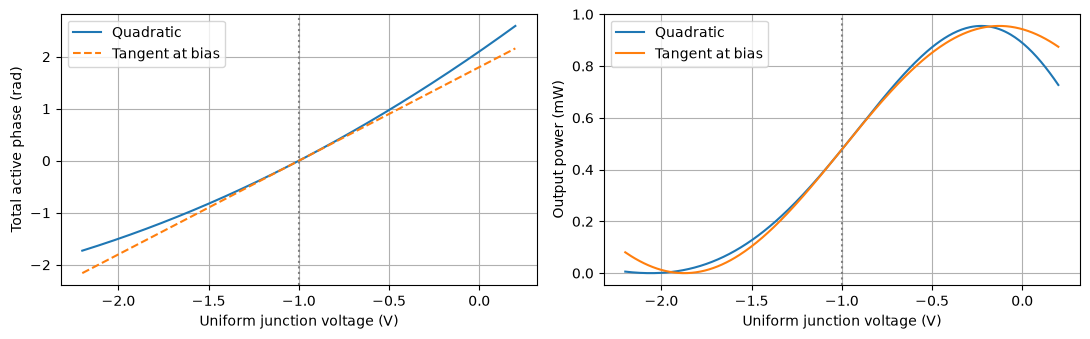

In [5]:
v_plot = np.linspace(-2.2, 0.2, 301)
phi_quadratic = length_mm * (phase_a1 * (v_plot - v_bias) + phase_a2 * (v_plot**2 - v_bias**2))
phi_tangent = length_mm * slope_per_mm * (v_plot - v_bias)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(v_plot, phi_quadratic, label="Quadratic")
axes[0].plot(v_plot, phi_tangent, "--", label="Tangent at bias")
axes[0].set(xlabel="Uniform junction voltage (V)", ylabel="Total active phase (rad)")
for phase, label in ((phi_quadratic, "Quadratic"), (phi_tangent, "Tangent at bias")):
    axes[1].plot(v_plot, transmitted_power * (1 + np.sin(phase)) / 2 * 1e3, label=label)
axes[1].set(xlabel="Uniform junction voltage (V)", ylabel="Output power (mW)")
for ax in axes:
    ax.axvline(v_bias, color="0.5", ls=":")
    ax.legend()
plt.tight_layout()
plt.show()

## 56 Gbaud transient

A UI is 17.857 ps. Use PRBS7 after a 64 UI constant preamble, with edges lasting 0.2 UI. Center the open-circuit source at $2V_b$ to account for the approximate source/load divider; solve the actual section biases at DC.

The source and CW operating point provide constant prehistory. Discard the preamble and first 16 data UIs when folding the eye. The first transient can take several minutes on CPU.

In [6]:
baud = 56e9
ui = 1 / baud
samples_per_ui = 32
sample_dt = ui / samples_per_ui
integration_dt = sample_dt / 2
preamble_bits = 64


def prbs7():
    # x^7 + x^6 + 1, maximal-length nonzero seven-bit LFSR.
    state = 0x7F
    bits = []
    for _ in range(127):
        bits.append(state & 1)
        feedback = ((state >> 0) ^ (state >> 1)) & 1
        state = (state >> 1) | (feedback << 6)
    assert state == 0x7F
    assert sum(bits) == 64
    return np.asarray(bits)


pattern = prbs7()
bits = np.r_[np.full(preamble_bits, pattern[0]), pattern]
levels = 2 * v_bias + source_vpp * (bits - 0.5)
edge = 0.2 * ui
pwl_t, pwl_v = [0.0], [float(levels[0])]
for k in range(1, len(bits)):
    if levels[k] != levels[k - 1]:
        pwl_t.extend([k * ui, k * ui + edge])
        pwl_v.extend([float(levels[k - 1]), float(levels[k])])
t_stop = len(bits) * ui
pwl_t.append(t_stop)
pwl_v.append(float(levels[-1]))
drive_settings = {"kind": WAVE_PWL, "pwl_t": jnp.asarray(pwl_t), "pwl_v": jnp.asarray(pwl_v)}
# Verify the generated PWL waveform against its intended symbol levels below.
mzm_net["instances"]["VS"]["settings"] = drive_settings
mzm = compile_circuit(mzm_net, mixed_models, is_complex=True, rtol=1e-9, atol=1e-10)
sample_times = jnp.arange(len(bits) * samples_per_ui + 1) * sample_dt


def run_transient(circuit, dt):
    started = time.perf_counter()
    solution = circuit.transient(
        t0=0.0, t1=t_stop, dt0=dt, saveat=sample_times, max_steps=int(np.ceil(t_stop / dt)) + 20, throw=True
    )
    solution.ys.block_until_ready()
    print(f"Transient: {time.perf_counter() - started:.1f} s; {solution.stats['num_steps']} steps")
    return solution


solution = run_transient(mzm, integration_dt)
optical_field = np.asarray(mzm.port(solution.ys, "optical_output"))
power = np.abs(optical_field) ** 2
source_wave = np.asarray(mzm.port(solution.ys, "VS,p1")).real
at_centers = (np.arange(len(bits)) * samples_per_ui + samples_per_ui // 2).astype(int)
np.testing.assert_allclose(source_wave[at_centers], levels, atol=1e-7)
assert np.all(np.isfinite(power))
assert power.max() <= transmitted_power * 1.001
print(f"UI: {ui * 1e12:.3f} ps; integration step: {integration_dt * 1e12:.3f} ps")

Transient: 158.4 s; 12224 steps
UI: 17.857 ps; integration step: 0.279 ps


## Compare phase curvature

Set $a_2=0$ and $a_1\leftarrow a_1+2a_2V_{b,k}$ to obtain each section's tangent at its DC bias. Both runs retain nonlinear MZM interference; their difference shows the effect of quadratic phase curvature.

Transient: 175.9 s; 12224 steps


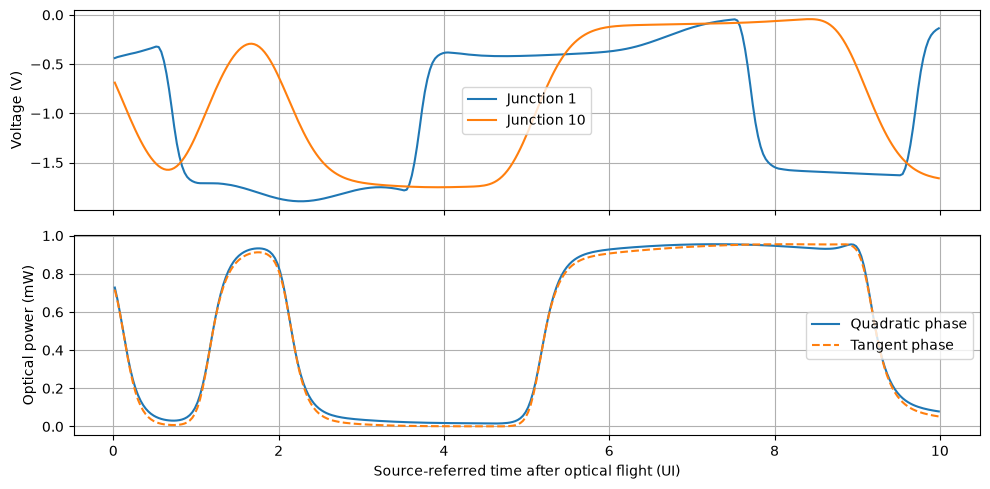

In [7]:
tangent_net = copy.deepcopy(mzm_net)
for k in range(n_sections):
    tangent_net["instances"][f"PS{k}"]["settings"].update(a1=float(section_slopes[k]), a2=0.0)
tangent_mzm = compile_circuit(tangent_net, mixed_models, is_complex=True, rtol=1e-9, atol=1e-10)
tangent_solution = run_transient(tangent_mzm, integration_dt)
tangent_power = np.abs(np.asarray(tangent_mzm.port(tangent_solution.ys, "optical_output"))) ** 2

# Plot a settled excerpt on a source-referred clock; remove only the common optical flight time.
clock_ui = (np.asarray(sample_times) - optical_tof) / ui
start_ui = preamble_bits + 16 + 10
mask = (clock_ui >= start_ui) & (clock_ui <= start_ui + 10)
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for k in (0, n_sections - 1):
    axes[0].plot(
        clock_ui[mask] - start_ui, np.asarray(mzm.port(solution.ys, f"junction_{k}"))[mask].real, label=f"Junction {k + 1}"
    )
axes[0].set(ylabel="Voltage (V)")
axes[0].legend()
axes[1].plot(clock_ui[mask] - start_ui, power[mask] * 1e3, label="Quadratic phase")
axes[1].plot(clock_ui[mask] - start_ui, tangent_power[mask] * 1e3, "--", label="Tangent phase")
axes[1].set(xlabel="Source-referred time after optical flight (UI)", ylabel="Optical power (mW)")
axes[1].legend()
plt.tight_layout()
plt.show()

## Fold the eye

Fold two-UI windows using the source clock plus the known optical flight time. This removes common latency while retaining RF/optical mismatch and junction response. Omit the last few bits so all windows stay inside the simulated record.

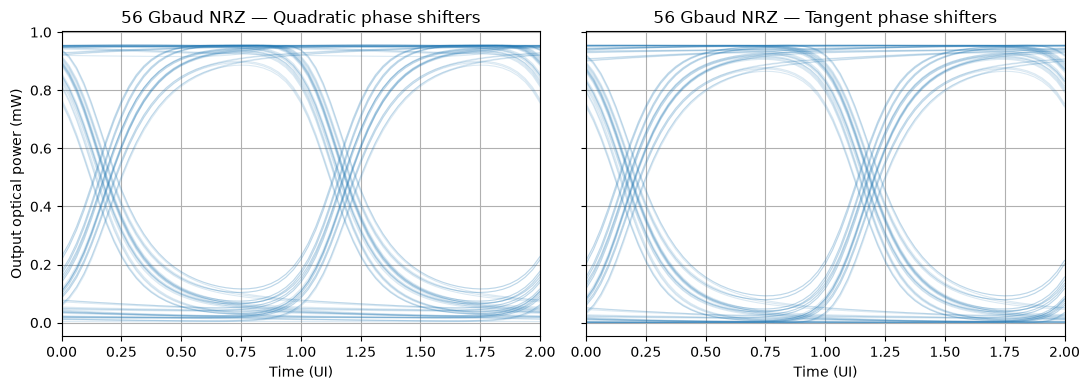

Folded 106 settled two-UI traces; PRBS7 period = 127 bits
Peak curvature effect on settled waveform: 0.034 mW


In [8]:
eye_start_bit = preamble_bits + 16
eye_bits = np.arange(eye_start_bit, len(bits) - 5)
eye_axis = np.arange(2 * samples_per_ui + 1) / samples_per_ui


def eye_traces(waveform):
    query = optical_tof + (eye_bits[:, None] + eye_axis[None, :]) * ui
    assert query.max() < float(sample_times[-1])
    return np.interp(query.ravel(), np.asarray(sample_times), waveform).reshape(query.shape)


quadratic_eye = eye_traces(power)
tangent_eye = eye_traces(tangent_power)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, traces, title in zip(
    axes, (quadratic_eye, tangent_eye), ("Quadratic phase shifters", "Tangent phase shifters"), strict=True
):
    ax.plot(eye_axis, traces.T * 1e3, color="C0", alpha=0.16, lw=0.8)
    ax.set(xlabel="Time (UI)", title=f"56 Gbaud NRZ — {title}", xlim=(0, 2))
axes[0].set_ylabel("Output optical power (mW)")
plt.tight_layout()
plt.show()
print(f"Folded {len(eye_bits)} settled two-UI traces; PRBS7 period = {len(pattern)} bits")
print(f"Peak curvature effect on settled waveform: {np.max(np.abs(quadratic_eye - tangent_eye)) * 1e3:.3f} mW")
assert np.max(np.abs(quadratic_eye - tangent_eye)) > 0.01 * transmitted_power

Try changing optical group index, load resistance, junction R/C or phase curvature, then rerun from the parameter cell. The eye is a finite-pattern example with ideal detection and no receiver noise or equalization.

A separate step-halving check gave a maximum settled-power difference of 0.364% of full scale. To repeat it, halve `integration_dt` and compare the eye traces.